<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_072_tsne.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 72/365 — t-SNE
## How can we visualize high-dimensional data in just 2 dimensions?

Yesterday we explored **PCA**.

PCA is a linear dimensionality-reduction method.

Today we move to one of the most popular high-dimensional visualization techniques:

**t-SNE — t-distributed Stochastic Neighbor Embedding**

Its main strength is preserving local neighborhood structure so complex data can be visualized in 2D or 3D.


In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE


## 1. Load the Digits dataset


In [2]:
digits=load_digits()

X=digits.data
y=digits.target

print("Dataset shape:",X.shape)
print("Features per image:",X.shape[1])
print("Classes:",len(set(y)))


Dataset shape: (1797, 64)
Features per image: 64
Classes: 10


## 2. Scale the data


In [3]:
X_scaled=StandardScaler().fit_transform(X)


## 3. First visualize with PCA


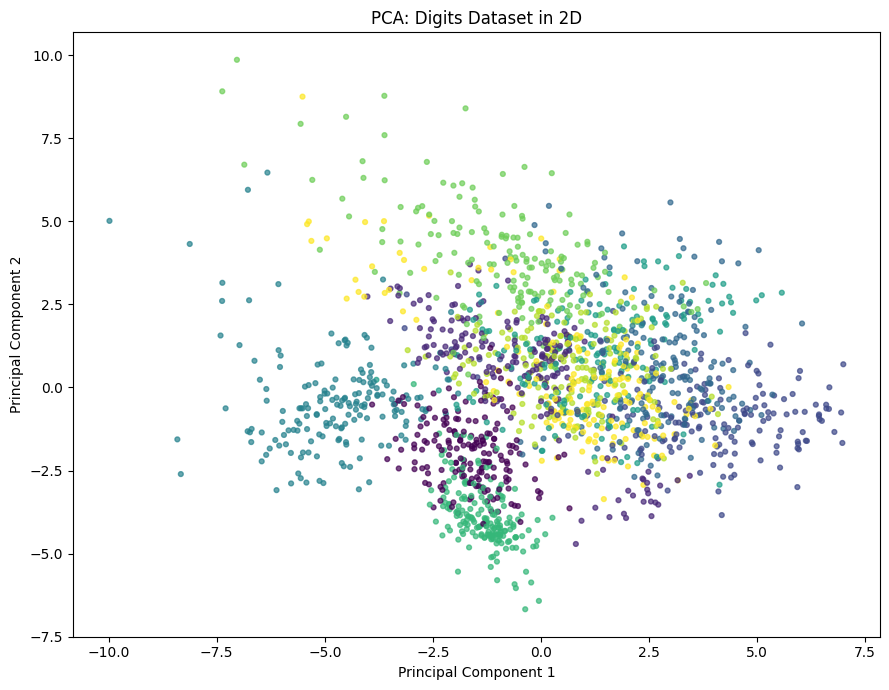

In [4]:
pca=PCA(n_components=2)

X_pca=pca.fit_transform(X_scaled)

plt.figure(figsize=(9,7))
plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=y,
    s=12,
    alpha=0.7
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Digits Dataset in 2D")
plt.tight_layout()
plt.show()


## 4. Apply t-SNE

t-SNE tries to keep nearby points close together in the lower-dimensional representation.


In [5]:
tsne=TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

X_tsne=tsne.fit_transform(X_scaled)

print("t-SNE output shape:",X_tsne.shape)


t-SNE output shape: (1797, 2)


## 5. Visualize the t-SNE map


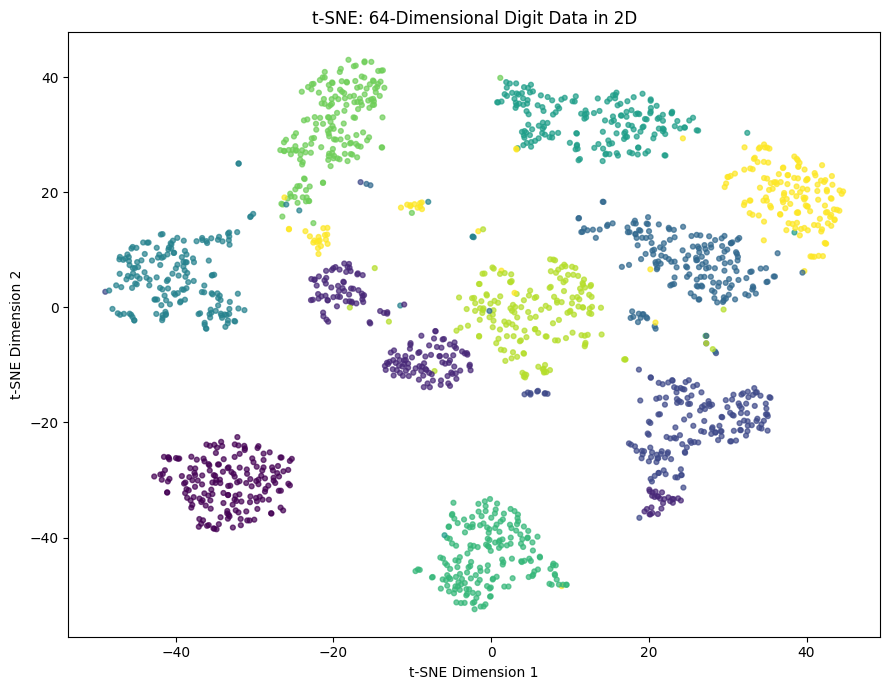

In [6]:
plt.figure(figsize=(9,7))

plt.scatter(
    X_tsne[:,0],
    X_tsne[:,1],
    c=y,
    s=12,
    alpha=0.7
)

plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.title("t-SNE: 64-Dimensional Digit Data in 2D")
plt.tight_layout()
plt.show()


## 6. PCA vs t-SNE

### PCA
- linear
- fast
- deterministic
- useful for compression and preprocessing
- preserves broad variance structure

### t-SNE
- nonlinear
- slower
- mainly for visualization
- focuses strongly on local neighborhood structure
- often reveals visually separated groups


## 7. Perplexity

`perplexity` roughly controls the neighborhood scale considered by t-SNE.

Smaller values emphasize very local relationships.

Larger values consider broader neighborhoods.

There is no universal best value.


## 8. Important warning

t-SNE plots can be misleading if over-interpreted.

- distances between far-away clusters are not necessarily meaningful
- cluster sizes are not necessarily meaningful
- parameter choices can change the visual
- t-SNE does not prove that true classes exist

Treat it as an exploratory visualization tool.


## Enterprise intuition

Organizations may have thousands of high-dimensional vectors:

- document embeddings
- customer embeddings
- image embeddings
- ticket embeddings
- behavior vectors

Humans cannot visualize 100 or 1,000 dimensions.

t-SNE can project them to 2D so we can inspect clusters, outliers, and local similarity patterns.


## What does this teach?

- t-SNE is nonlinear dimensionality reduction.
- It is mainly used for visualization.
- It preserves local neighborhood structure.
- It can reveal patterns that PCA may not show as clearly.
- Perplexity affects the result.
- The plot must be interpreted cautiously.

> **PCA asks which directions explain the most variance. t-SNE asks which points should remain neighbors when the data is squeezed into 2D.**


## References

- https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html
- https://scikit-learn.org/stable/modules/manifold.html#t-sne
- https://www.jmlr.org/papers/v9/vandermaaten08a.html
- https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html
